# Obrasgov infrastructure locations

Saved project records are split into geometry components, screened for location problems, checked against their reported state, and exported as `obrasgov_screened_locations.gpkg`. The notebook owns this sequence; `datasets/run.py obrasgov` executes these cells.

**Source:** the original extraction paged [Obrasgov](https://www.gov.br/obrasgov/pt-br/acesso-a-informacao/dados-abertos-obrasgov) records and joined nested intervention and CIPI geometry data. This build begins with the preserved `projects_st.gpkg`; exact historical API responses and capture time are unavailable. [Extraction method](https://github.com/fab1s/brazil-project/blob/archive/full-project-2026-10-27/data/archive/original_code/Scripts_Data/Obrasgov/Obrasgov%20-%20Data%20Extraction.qmd) · [settings and reference paths](../project.toml) · [codebook](CODEBOOK.md).

In [1]:
%run ../_shared.py
ctx = notebook_context("obrasgov")
import pandas as pd
from IPython.display import display

## 1. Source records and category labels

A source row describes a reported project/intervention and can carry several geometric parts. The original snapshot stage adds category labels and produces a historical cleaned comparison. The location workflow below always reads the unchanged source GeoPackage, preserving its coordinates and investment values. [Snapshot code](../shared/brazil_project/infrastructure/projects.py).

In [2]:
source = ctx.path("infrastructure", "obrasgov")
display(geopackage_inventory(source))
process_stage(ctx, "obrasgov-snapshot")
snapshot = json.loads(ctx.require(ctx.artifact("obrasgov", "report.json")).read_text())
display(pd.DataFrame([{"Source rows": snapshot["records"], "Historical cleaned rows": snapshot["cleaned_records"]}]))
display(sql_table(source, 'SELECT id_projeto_investimento, tipo, subtipo, uf_principal FROM projects_st LIMIT 5'))

,Layer,Rows,Geometry,CRS
0,projects_st,134929,Unknown,EPSG:4674


Using saved obrasgov-snapshot outputs


,Source rows,Historical cleaned rows
0,134929,133417


,id_projeto_investimento,tipo,subtipo,uf_principal
0,72343.33-91,"Infraestrutura Hídrica, Portos, Hidrovia","Dragagem, Derrocamento e Associações",RJ
1,99674.21-93,Infraestrutura Urbana e Mobilidade,Drenagem,MA
2,110292.31-20,Saúde,Unidades de Atenção Especializada de Saúde,MG
3,97114.31-26,Desenvolvimento,Estradas Vicinais,MG
4,102443.35-00,Educação,Educação,SP


## 2. Geometry components and screening

Each point, line, or polygon part gets a stable `component_id`; the original project ID can repeat. The checks flag missing/invalid geometry, nonfinite or world-range errors, and implausible offshore or administrative locations. Lines use 1 km regular samples, capped at 250, plus their original vertices. The configured 5 km coast and 1 km border tolerances are screening rules, not verified geocoding accuracy. Polygons are preserved in the audit and omitted from this map derivative. [Decomposition and screening code](../shared/brazil_project/infrastructure/location_qa.py).

Using saved obrasgov-location-qa outputs


,geometry_type,location_status,Components
0,LineString,administrative_or_coordinate_review,721
1,LineString,eligible_unverified,23460
2,MultiPoint,quarantined_invalid_location,1509
3,Point,administrative_or_coordinate_review,1342
4,Point,border_review,62
5,Point,coastal_review,75
6,Point,eligible_unverified,200643
7,Point,possible_marine_review,6
8,Point,quarantined_invalid_location,14
9,Point,quarantined_offshore,428


,All components,Initially eligible
geometry_type,,
LineString,24181,24181
MultiPoint,1509,0
Point,202656,202128
Polygon,2010,0


Using saved obrasgov-location-plot outputs


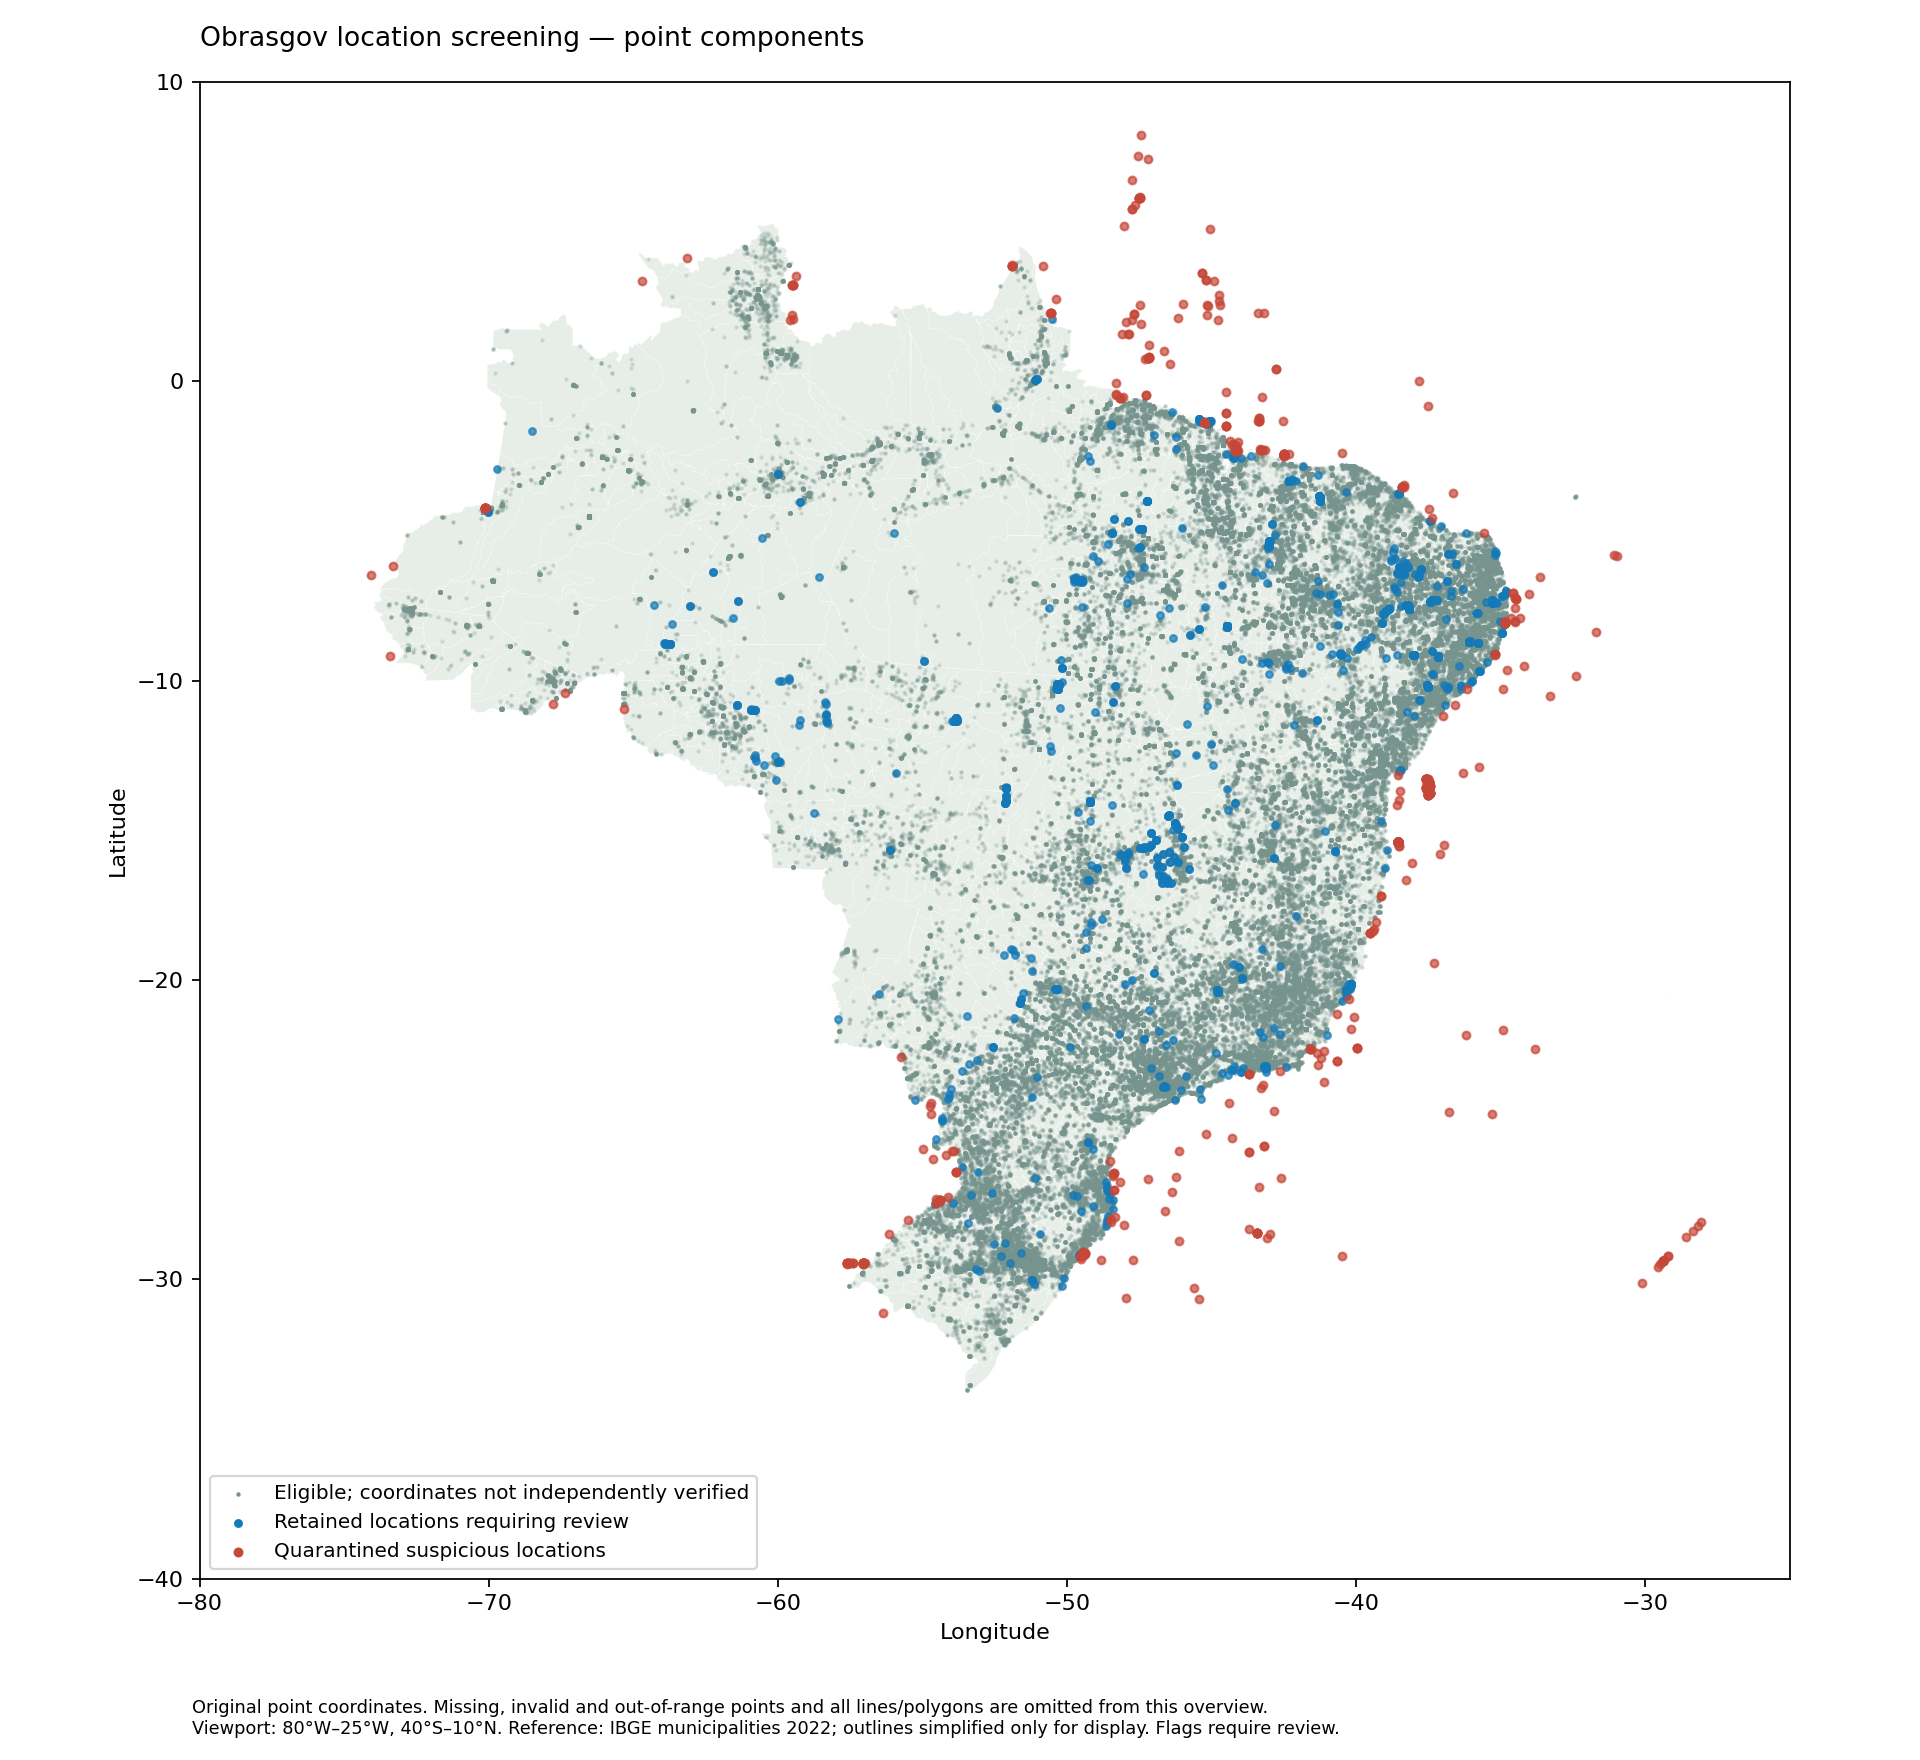

In [3]:
process_stage(ctx, "obrasgov-location-qa")
components = pd.read_parquet(ctx.artifact("obrasgov-location-qa", "component_audit.parquet"),
    columns=["component_id", "project_id", "geometry_type", "location_status", "map_eligible"])
assert components.component_id.is_unique
display(components.groupby(["geometry_type", "location_status"], dropna=False).size().rename("Components").reset_index())
display(components.groupby("geometry_type").map_eligible.agg(["size", "sum"]).rename(columns={"size":"All components", "sum":"Initially eligible"}))
process_stage(ctx, "obrasgov-location-plot")
show_image(ctx, "outputs/figures/obrasgov-location-qa/location-screening.png")

## 3. Complete geometry versus primary state

The state check uses the whole geometry. A component is classified as fully inside, partly inside/boundary contact, entirely outside, or unassessable. It checks the reported primary state, which can incompletely describe a multi-state project. This step records classifications. [State-check code](../shared/scripts/check_obras_primary_state.py).

In [4]:
process_stage(ctx, "obrasgov-primary-state-check")
checks = pd.read_csv(ctx.root / "outputs/tables/obrasgov-primary-state/components.csv", keep_default_na=False,
                    dtype={"component_id": str}, usecols=["component_id", "primary_state_check", "intersected_states"])
assert checks.component_id.is_unique
assert set(checks.component_id) == set(components.component_id)
display(checks.primary_state_check.value_counts().rename_axis("State relation").reset_index(name="Components"))

Using saved obrasgov-primary-state-check outputs


,State relation,Components
0,fully_inside,226006
1,entirely_outside,2346
2,not_assessable_geometry,1561
3,partly_inside_or_boundary_contact,440
4,unknown_or_missing_primary_state,3


## 4. Approved exclusion rule

Keep a component when it passed the first screen **and** is not entirely outside its primary state. Partial/boundary intersections remain subject to the first screen. The two Boolean rules below are the rules used by the [production filter](../shared/scripts/filter_obras_primary_state.py); joins use component IDs because project IDs can repeat.

,Initially eligible,Excluded by state rule (all components),Newly excluded from eligible set,Final eligible
0,226309,2346,1814,224495


Using saved obrasgov-primary-state-filter outputs


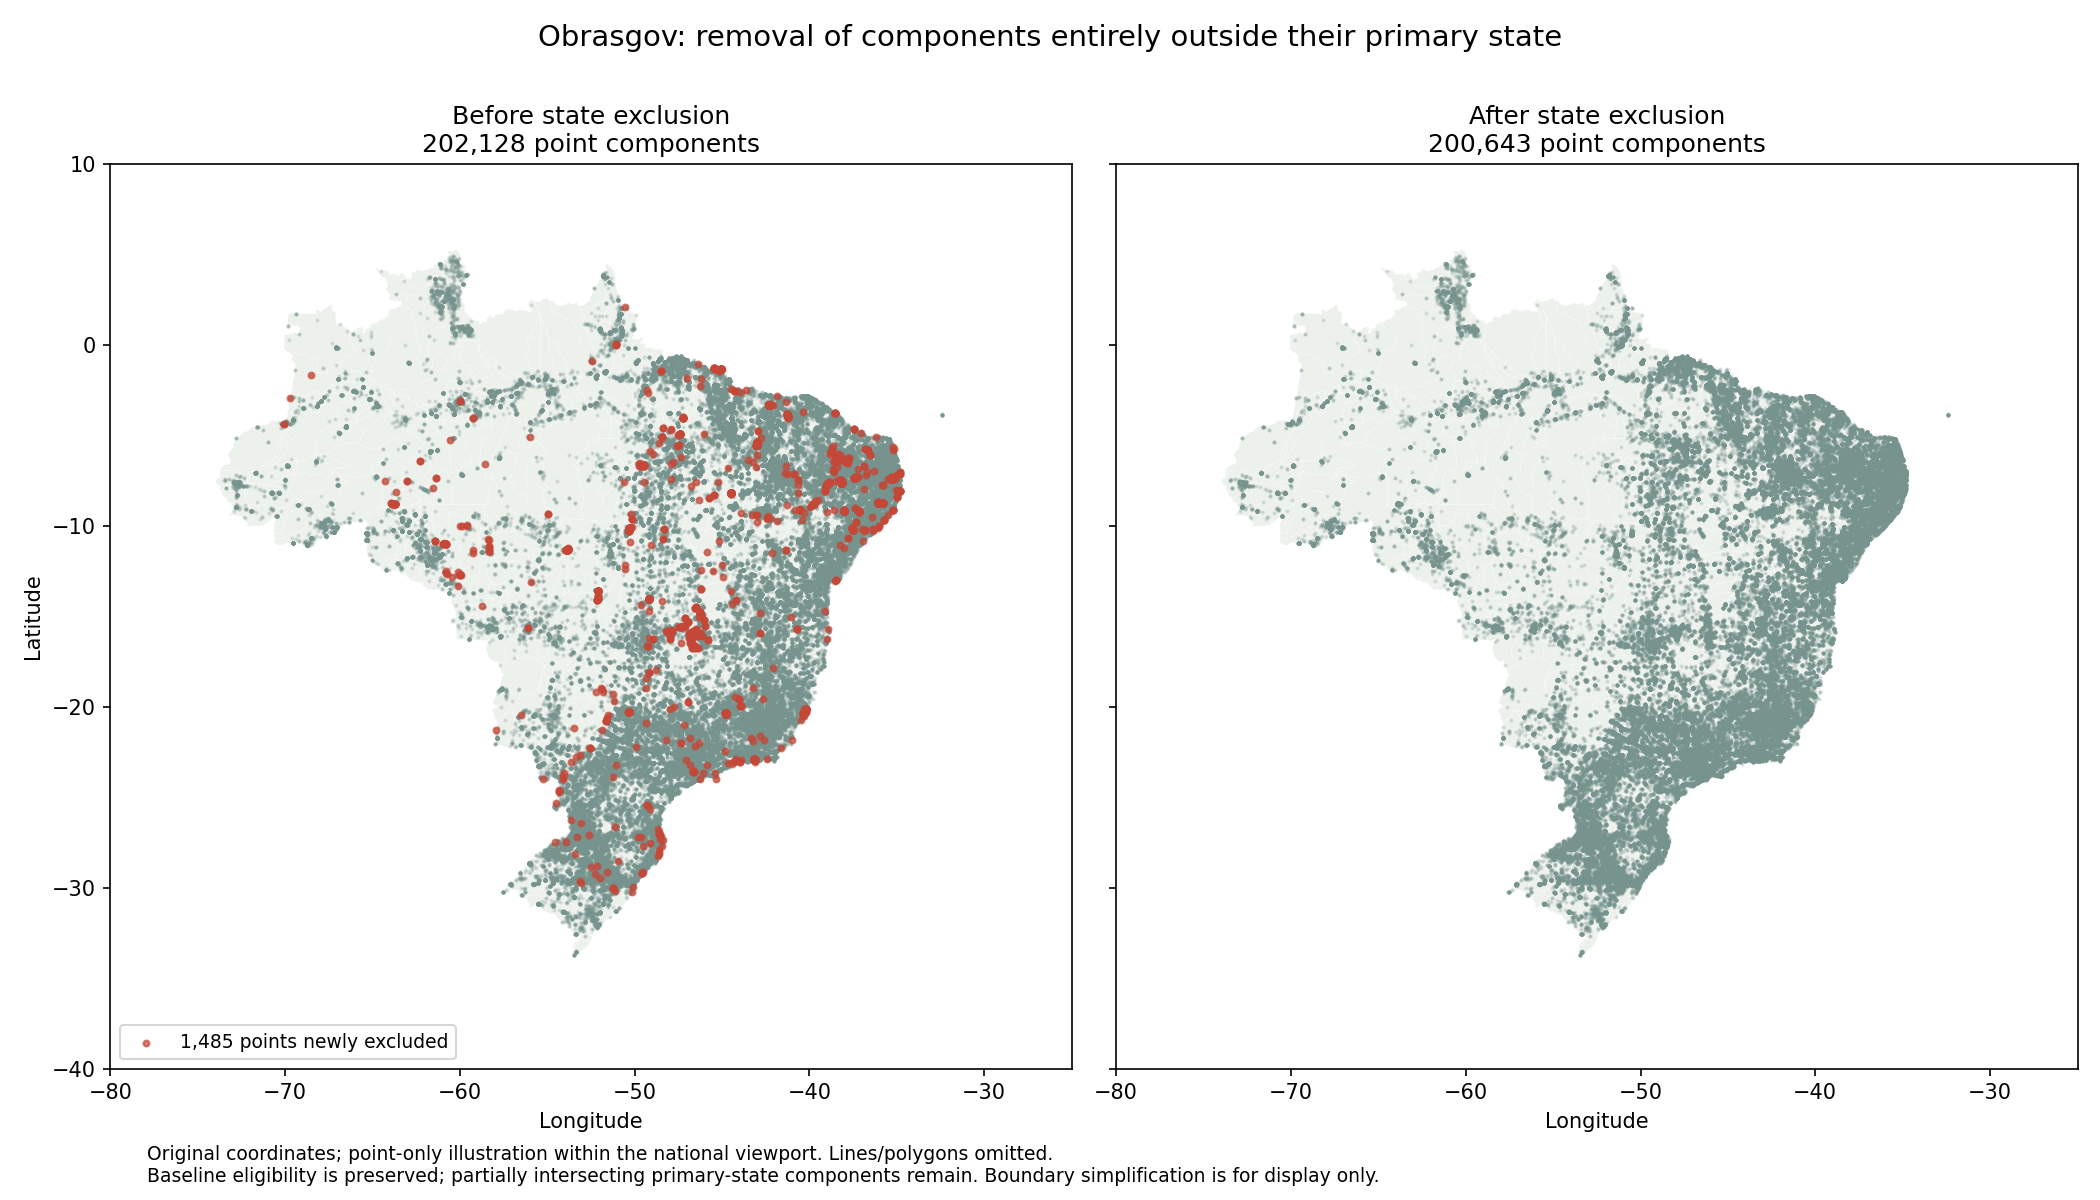

In [5]:
from scripts.filter_obras_primary_state import apply_filter
decisions = apply_filter(components, checks)
assert decisions.primary_state_excluded.equals(decisions.primary_state_check.eq("entirely_outside"))
assert decisions.final_map_eligible.equals(decisions.map_eligible & ~decisions.primary_state_excluded)
display(pd.DataFrame([{"Initially eligible": int(decisions.map_eligible.sum()),
    "Excluded by state rule (all components)": int(decisions.primary_state_excluded.sum()),
    "Newly excluded from eligible set": int((decisions.map_eligible & decisions.primary_state_excluded).sum()),
    "Final eligible": int(decisions.final_map_eligible.sum())}]))
process_stage(ctx, "obrasgov-primary-state-filter")
saved_ids = pd.read_parquet(ctx.artifact("obrasgov-primary-state-filter", "map_components.parquet"), columns=["component_id"])
assert set(saved_ids.component_id) == set(decisions.loc[decisions.final_map_eligible, "component_id"])
show_image(ctx, "outputs/figures/obrasgov-location-qa/primary-state-filter.png")

The comparison figure shows eligible **points** before and after the state rule. Lines, polygons, and previously quarantined points are omitted. Original records remain preserved; exclusion is a researcher's display policy rather than proof that every excluded coordinate is wrong.

## 5. English export

`map_components` contains retained points and lines; `excluded_primary_state` contains all state-rule exclusions, including components already absent after the first screen. English category values accompany the originals. Place names and free-form descriptions retain their original text. The [export helper](processing.py) verifies IDs, source attributes, CRS, and exact geometry before publishing.

In [6]:
from processing import export_saved, inspect_final
result = inspect_final(ctx.root) if ctx.notebook_from_saved else export_saved(ctx.root)
show_final(ctx, result)
display(sql_table(result["file"], "SELECT project_type_original, project_type_english, COUNT(*) AS components FROM map_components GROUP BY project_type_original, project_type_english ORDER BY components DESC LIMIT 8"))
display(sql_table(result["file"], "SELECT source_field, original_value_column, english_value_column FROM field_dictionary LIMIT 10"))

,File,Layer,Features,CRS
0,datasets/obrasgov/obrasgov_screened_locations....,map_components,224495,EPSG:4674


SHA-256: 663c1106e99d53824b0e8ba7f2c31e1eb6d37b382c02c83c588e2f02c120dae6


,project_type_original,project_type_english,components
0,Saúde,Health,46272
1,Infraestrutura Urbana e Mobilidade,Urban Infrastructure and Mobility,43074
2,"Infraestrutura Hídrica, Portos, Hidrovia","Water Infrastructure, Ports, and Waterways",32559
3,Rodovia,Highways,31534
4,Desenvolvimento,Development,20653
5,Educação,Education,18251
6,Defesa Civil,Civil Defense,6669
7,Administrativo,Administrative,6151


,source_field,original_value_column,english_value_column
0,declared_uf,declared_state,None
1,id_projeto_investimento,investment_project_id,None
2,projeto_estruturante,strategic_project_original,strategic_project_english
3,desc_nome,project_name_original,None
4,nr_cep,postal_code,None
5,desc_endereco,address_original,None
6,desc_projeto,project_description_original,None
7,desc_funcao_social,social_purpose_original,None
8,desc_meta_global,overall_goal_original,None
9,dt_inicial_prevista,planned_start_date,None


**Use:** eligible locations support geographic analysis with the documented limits. Count distinct project IDs for project totals; investment values repeat across geometry components. This build does not independently verify every location or publish the website.

<details><summary>Execution verification</summary>

The full national notebook command completed on 2026-10-27. All 224,495 retained and 2,346 excluded component records matched the preceding reviewed export in IDs, attributes, and geometry blobs. This is processing parity, rather than independent scientific validation.

</details>